In [1]:
import time
from pathlib import Path
import pandas as pd
import plotly.graph_objects as go
from plotly.subplots import make_subplots
from IPython.display import clear_output, display

DATA_DIR = (
    Path("data/streaming_output")
    if Path("data/streaming_output").exists()
    else Path("../data/streaming_output")
)

def load_streaming_data() -> pd.DataFrame:
    files = list(DATA_DIR.glob("*.parquet"))
    if not files:
        return pd.DataFrame()
    
    dfs = []
    for f in files:
        try:
            dfs.append(pd.read_parquet(f))
        except Exception:
            continue
            
    return pd.concat(dfs, ignore_index=True) if dfs else pd.DataFrame()

print(f"Reading stream from: {DATA_DIR.resolve()}")

Reading stream from: /home/nikan/Documents/nyc-taxi-bigdata-pipeline/data/streaming_output


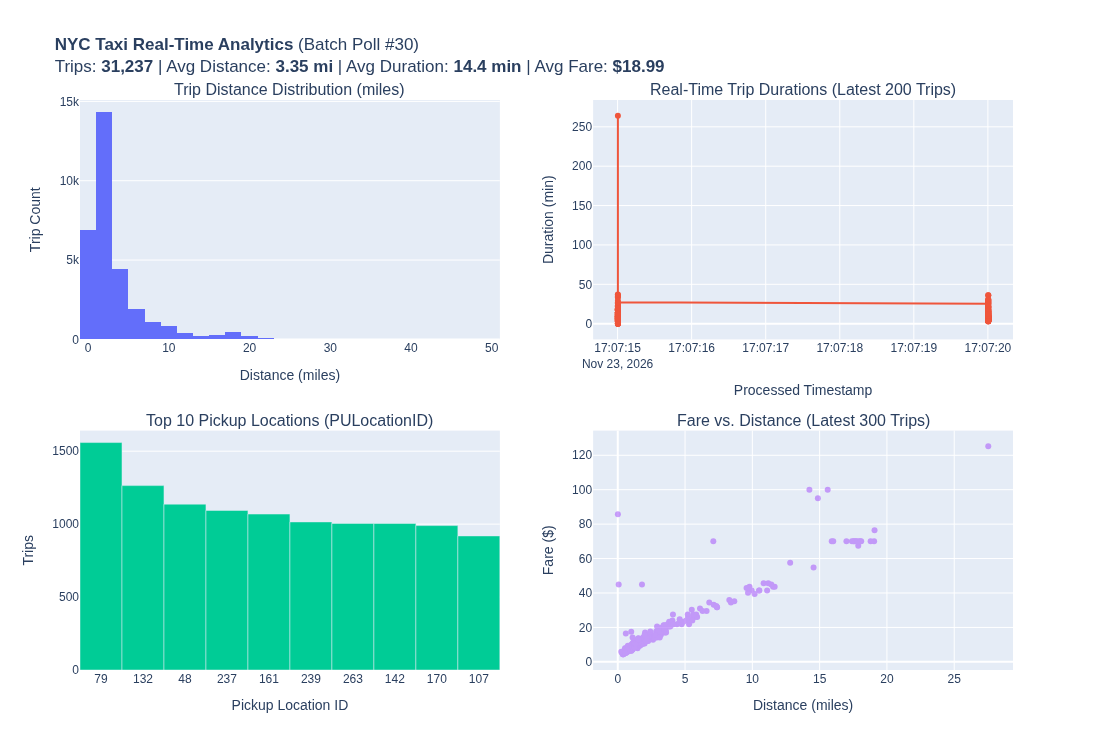

Live stream polling stopped.


In [2]:
REFRESH_SECONDS = 5
MAX_ITERATIONS = 60  # Runs for ~5 minutes; interrupt anytime

try:
    for iteration in range(1, MAX_ITERATIONS + 1):
        df = load_streaming_data()
        clear_output(wait=True)

        if df.empty:
            print(f"[Refresh {iteration}] Waiting for Spark Streaming micro-batches...")
            time.sleep(REFRESH_SECONDS)
            continue

        # Filter extreme outliers for clean chart scaling
        df_clean = df[(df["trip_distance"] > 0) & (df["trip_distance"] <= 50)].copy()

        total_trips = len(df_clean)
        avg_dist = df_clean["trip_distance"].mean()
        avg_dur = df_clean["trip_duration_min"].mean()
        avg_fare = df_clean["fare_amount"].mean()

        fig = make_subplots(
            rows=2,
            cols=2,
            subplot_titles=(
                "Trip Distance Distribution (miles)",
                "Real-Time Trip Durations (Latest 200 Trips)",
                "Top 10 Pickup Locations (PULocationID)",
                "Fare vs. Distance (Latest 300 Trips)",
            ),
            vertical_spacing=0.16,
            horizontal_spacing=0.10,
        )

        # 1. Trip Distance Distribution
        fig.add_trace(
            go.Histogram(x=df_clean["trip_distance"], nbinsx=30, name="Distance (mi)"),
            row=1, col=1,
        )

        # 2. Real-Time Trip Durations
        recent = df_clean.sort_values("processed_at").tail(200)
        fig.add_trace(
            go.Scatter(
                x=recent["processed_at"],
                y=recent["trip_duration_min"],
                mode="lines+markers",
                name="Duration (min)",
            ),
            row=1, col=2,
        )

        # 3. Top 10 Pickup Locations
        top_loc = (
            df_clean.groupby("PULocationID")
            .size()
            .reset_index(name="trips")
            .sort_values("trips", ascending=False)
            .head(10)
        )
        fig.add_trace(
            go.Bar(
                x=top_loc["PULocationID"].astype(str),
                y=top_loc["trips"],
                name="Trips",
            ),
            row=2, col=1,
        )

        # 4. Fare vs Distance
        sample_recent = df_clean.sort_values("processed_at").tail(300)
        fig.add_trace(
            go.Scatter(
                x=sample_recent["trip_distance"],
                y=sample_recent["fare_amount"],
                mode="markers",
                opacity=0.6,
                name="Fare ($)",
            ),
            row=2, col=2,
        )

        fig.update_layout(
            height=750,
            showlegend=False,
            title_text=(
                f"<b>NYC Taxi Real-Time Analytics</b> (Batch Poll #{iteration})<br>"
                f"Trips: <b>{total_trips:,}</b> | "
                f"Avg Distance: <b>{avg_dist:.2f} mi</b> | "
                f"Avg Duration: <b>{avg_dur:.1f} min</b> | "
                f"Avg Fare: <b>${avg_fare:.2f}</b>"
            ),
        )
        fig.update_xaxes(title_text="Distance (miles)", row=1, col=1)
        fig.update_yaxes(title_text="Trip Count", row=1, col=1)
        fig.update_xaxes(title_text="Processed Timestamp", row=1, col=2)
        fig.update_yaxes(title_text="Duration (min)", row=1, col=2)
        fig.update_xaxes(title_text="Pickup Location ID", row=2, col=1)
        fig.update_yaxes(title_text="Trips", row=2, col=1)
        fig.update_xaxes(title_text="Distance (miles)", row=2, col=2)
        fig.update_yaxes(title_text="Fare ($)", row=2, col=2)

        fig.show()
        time.sleep(REFRESH_SECONDS)

except KeyboardInterrupt:
    print("Live stream polling stopped.")

In [3]:
import ipywidgets as widgets
import plotly.express as px

df_snapshot = load_streaming_data()

@widgets.interact(
    max_miles=widgets.IntSlider(min=5, max=50, step=5, value=25, description="Max Miles:"),
    passengers=widgets.Dropdown(
        options=["All"] + sorted(df_snapshot["passenger_count"].unique().tolist()),
        value="All",
        description="Passengers:",
    ),
)
def explore_stream(max_miles, passengers):
    filtered = df_snapshot[df_snapshot["trip_distance"] <= max_miles]
    if passengers != "All":
        filtered = filtered[filtered["passenger_count"] == passengers]
    
    fig = px.histogram(
        filtered,
        x="trip_duration_min",
        nbins=30,
        title=f"Trip Duration Distribution (n = {len(filtered):,} trips, <= {max_miles} mi)",
        labels={"trip_duration_min": "Trip Duration (minutes)"},
    )
    fig.show()

interactive(children=(IntSlider(value=25, description='Max Miles:', max=50, min=5, step=5), Dropdown(descripti…